In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving url_features_extracted1.csv to url_features_extracted1.csv


In [3]:
df = pd.read_csv("url_features_extracted1.csv")

In [4]:
print("First 5 rows:")
print(df.head())

First 5 rows:
                                               URL  url_length  \
0  https://keraekken-loagginnusa.godaddysites.com/          47   
1         https://metamsk01lgiix.godaddysites.com/          40   
2                          http://myglobaltech.in/          23   
3                   http://djtool-for-spotify.com/          30   
4  https://scearmcoommunnlty.com/invent/freind/get          47   

   has_ip_address  dot_count  https_flag  url_entropy  token_count  \
0               0          2           1     4.250669            6   
1               0          2           1     4.196439            6   
2               0          1           0     3.936180            5   
3               0          1           0     3.894740            5   
4               0          1           1     4.143127            7   

   subdomain_count  query_param_count  tld_length  path_length  \
0                1                  1           3            1   
1                1                  

In [5]:
print("\nShape of dataset:")
print(df.shape)


Shape of dataset:
(101219, 18)


In [6]:
print("\nColumn names:")
print(df.columns)


Column names:
Index(['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag',
       'url_entropy', 'token_count', 'subdomain_count', 'query_param_count',
       'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits',
       'tld_popularity', 'suspicious_file_extension', 'domain_name_length',
       'percentage_numeric_chars', 'ClassLabel'],
      dtype='object')


In [7]:
print("\nDataset information:")
print(df.info())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101219 entries, 0 to 101218
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   URL                        101219 non-null  object 
 1   url_length                 101219 non-null  int64  
 2   has_ip_address             101219 non-null  int64  
 3   dot_count                  101219 non-null  int64  
 4   https_flag                 101219 non-null  int64  
 5   url_entropy                101219 non-null  float64
 6   token_count                101219 non-null  int64  
 7   subdomain_count            101219 non-null  int64  
 8   query_param_count          101219 non-null  int64  
 9   tld_length                 101219 non-null  int64  
 10  path_length                101219 non-null  int64  
 11  has_hyphen_in_domain       101219 non-null  int64  
 12  number_of_digits           101219 non-null  int64  
 13  tld_pop

In [8]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
URL                          0
url_length                   0
has_ip_address               0
dot_count                    0
https_flag                   0
url_entropy                  0
token_count                  0
subdomain_count              0
query_param_count            0
tld_length                   0
path_length                  0
has_hyphen_in_domain         0
number_of_digits             0
tld_popularity               0
suspicious_file_extension    0
domain_name_length           0
percentage_numeric_chars     0
ClassLabel                   1
dtype: int64


In [9]:
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Number of duplicate rows:
346


In [10]:
print("\nClass distribution:")
print(df["ClassLabel"].value_counts())


Class distribution:
ClassLabel
0.0    63678
1.0    37540
Name: count, dtype: int64


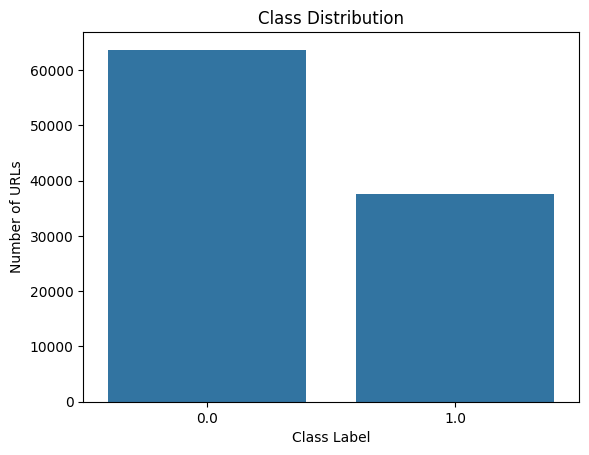

In [11]:
sns.countplot(x="ClassLabel", data=df)

plt.title("Class Distribution")
plt.xlabel("Class Label")
plt.ylabel("Number of URLs")

plt.show()

In [12]:
df = df.dropna(subset=["ClassLabel"])

In [13]:
df = df.drop_duplicates()

In [14]:
print("Shape after cleaning:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Shape after cleaning:
(100872, 18)

Missing values:
0

Duplicate rows:
0


In [15]:
X = df.drop("ClassLabel", axis=1)
y = df["ClassLabel"]

In [16]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Features shape: (100872, 17)
Target shape: (100872,)

Target classes:
ClassLabel
0.0    63492
1.0    37380
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (80697, 17)
Testing data: (20175, 17)

Training target distribution:
ClassLabel
0.0    50793
1.0    29904
Name: count, dtype: int64

Testing target distribution:
ClassLabel
0.0    12699
1.0     7476
Name: count, dtype: int64


In [19]:
print(df["ClassLabel"].value_counts())

ClassLabel
0.0    63492
1.0    37380
Name: count, dtype: int64


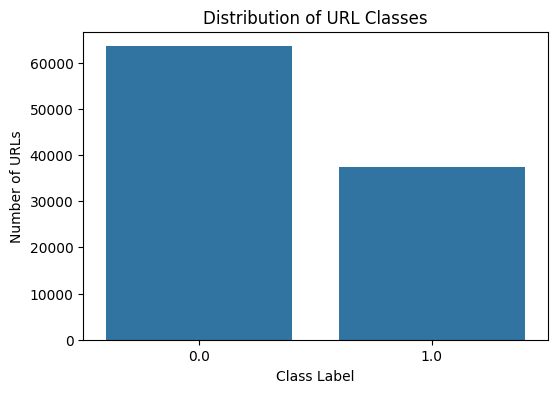

In [20]:
plt.figure(figsize=(6, 4))

sns.countplot(x="ClassLabel", data=df)

plt.title("Distribution of URL Classes")
plt.xlabel("Class Label")
plt.ylabel("Number of URLs")

plt.show()

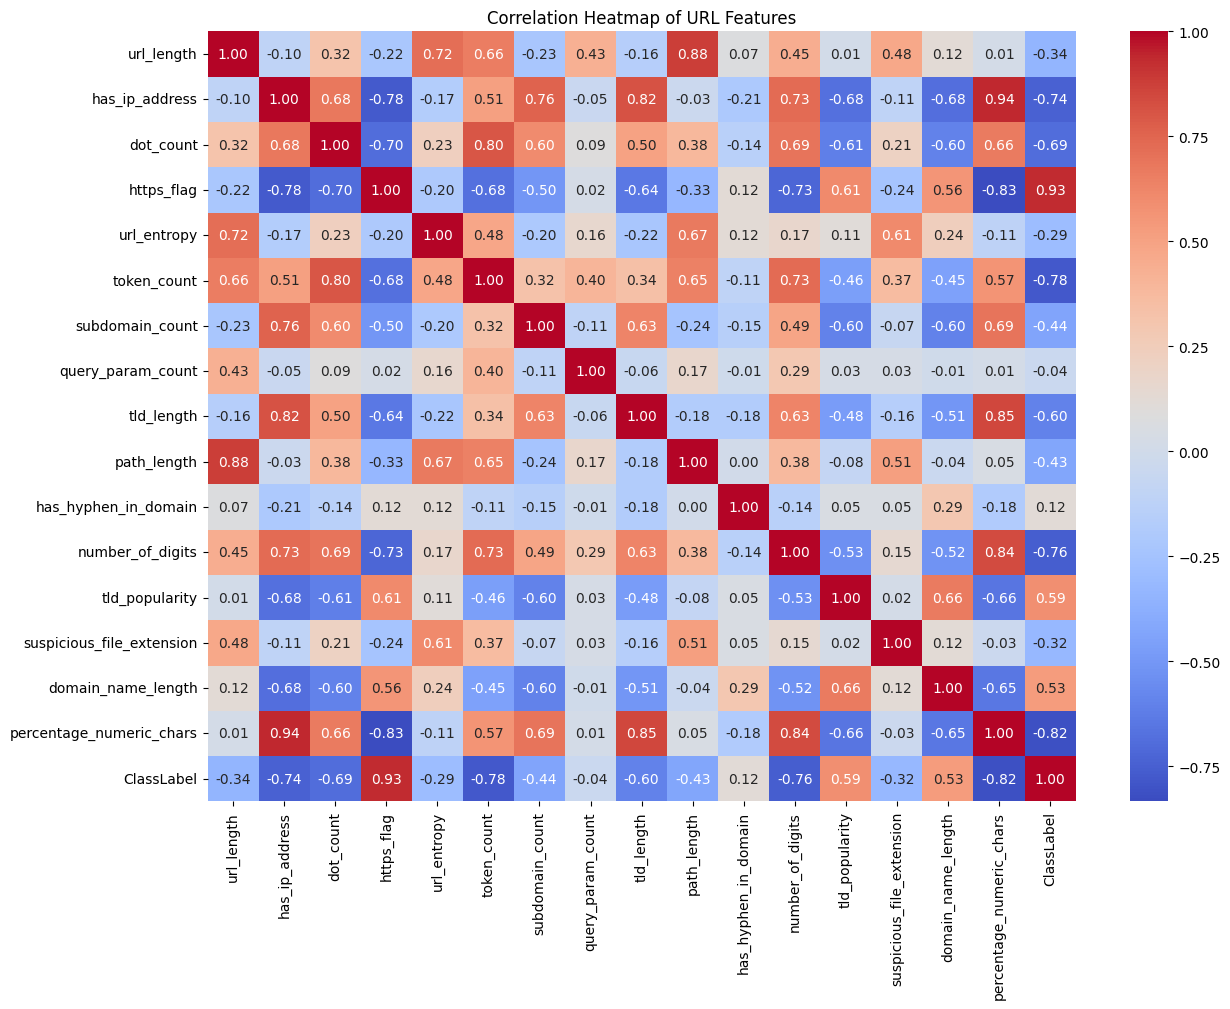

In [21]:
plt.figure(figsize=(14, 10))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of URL Features")

plt.show()

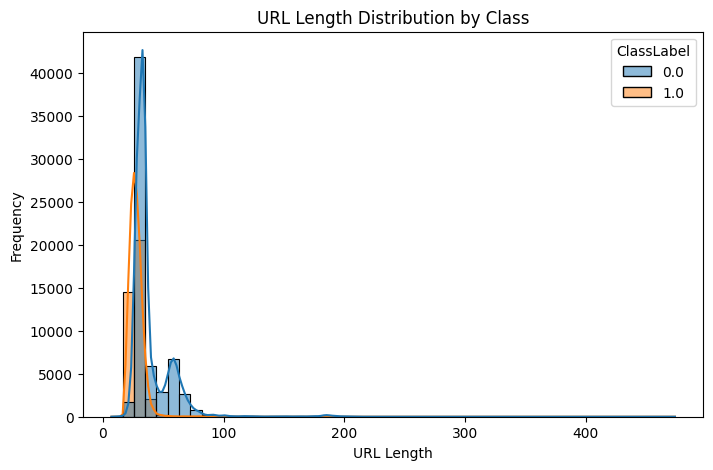

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="url_length",
    hue="ClassLabel",
    bins=50,
    kde=True
)

plt.title("URL Length Distribution by Class")
plt.xlabel("URL Length")
plt.ylabel("Frequency")

plt.show()

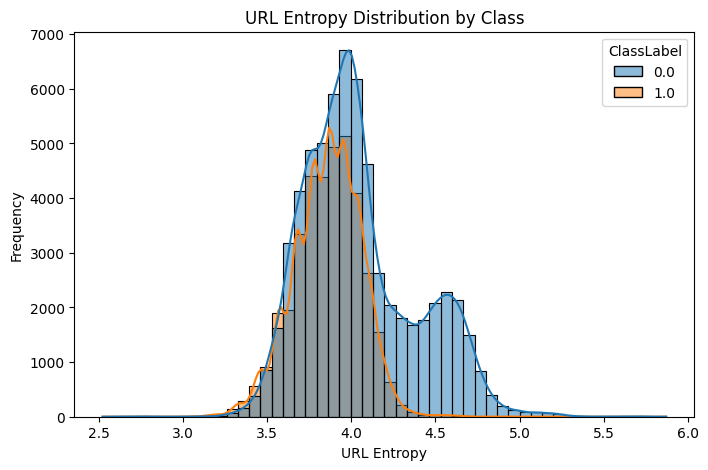

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="url_entropy",
    hue="ClassLabel",
    bins=50,
    kde=True
)

plt.title("URL Entropy Distribution by Class")
plt.xlabel("URL Entropy")
plt.ylabel("Frequency")

plt.show()

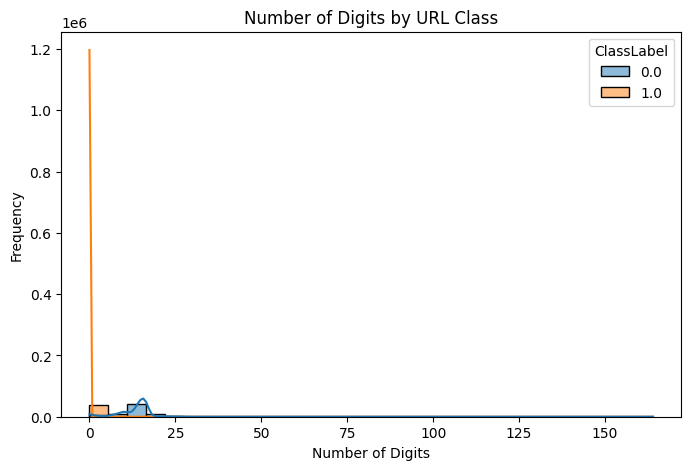

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="number_of_digits",
    hue="ClassLabel",
    bins=30,
    kde=True
)

plt.title("Number of Digits by URL Class")
plt.xlabel("Number of Digits")
plt.ylabel("Frequency")

plt.show()

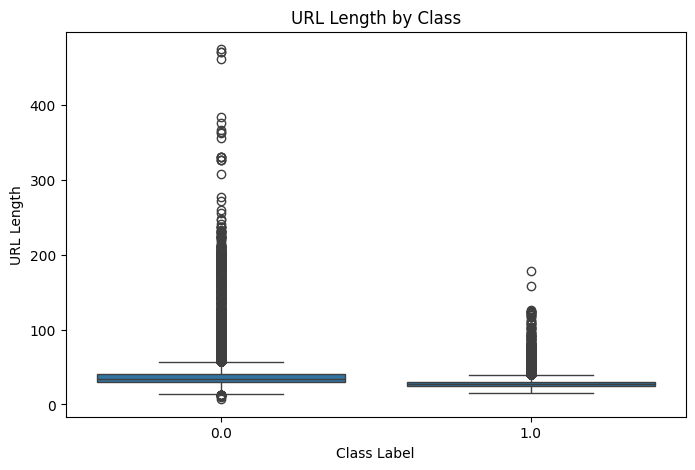

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="ClassLabel",
    y="url_length",
    data=df
)

plt.title("URL Length by Class")
plt.xlabel("Class Label")
plt.ylabel("URL Length")

plt.show()

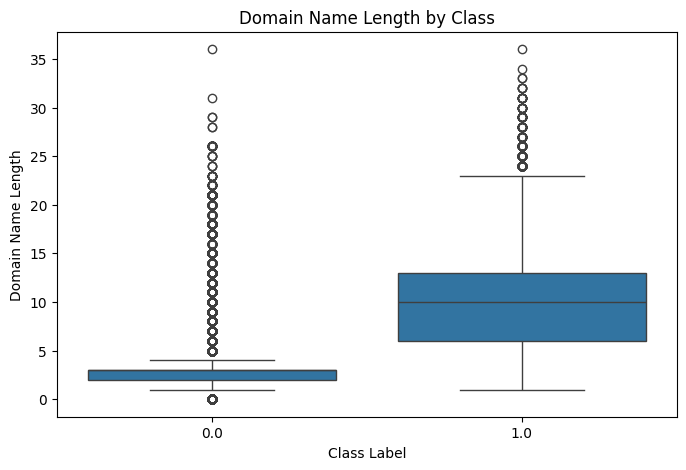

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="ClassLabel",
    y="domain_name_length",
    data=df
)

plt.title("Domain Name Length by Class")
plt.xlabel("Class Label")
plt.ylabel("Domain Name Length")

plt.show()

In [27]:
class_means = df.groupby("ClassLabel").mean(numeric_only=True)

print(class_means)

            url_length  has_ip_address  dot_count  https_flag  url_entropy  \
ClassLabel                                                                   
0.0          39.432889        0.770428   3.510033    0.055346     4.045377   
1.0          27.552675        0.000000   2.156742    0.999920     3.857945   

            token_count  subdomain_count  query_param_count  tld_length  \
ClassLabel                                                                
0.0            7.882584         1.721382           1.016868    6.341271   
1.0            5.186089         1.156394           1.000027    2.725762   

            path_length  has_hyphen_in_domain  number_of_digits  \
ClassLabel                                                        
0.0           13.303849              0.024570         13.475902   
1.0            0.351739              0.074371          0.072097   

            tld_popularity  suspicious_file_extension  domain_name_length  \
ClassLabel                              

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [29]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [30]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

In [31]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [32]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

In [33]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

In [34]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "SVM": svm_model,
    "XGBoost": xgb_model
}

In [36]:
results = []


X_train_numeric = X_train.drop(columns=['URL'], errors='ignore')
X_test_numeric = X_test.drop(columns=['URL'], errors='ignore')

for name, model in models.items():

    print("Training:", name)


    model.fit(X_train_numeric, y_train)

    y_pred = model.predict(X_test_numeric)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_numeric)[:, 1]
    else:
        y_prob = None

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    if y_prob is not None:
        auc = roc_auc_score(y_test, y_prob)
    else:
        auc = None

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    print("Accuracy:", accuracy)
    print()

Training: Logistic Regression
Accuracy: 0.9970260223048327

Training: Decision Tree
Accuracy: 0.9994052044609666

Training: Random Forest
Accuracy: 0.9995539033457249

Training: SVM
Accuracy: 0.9985625774473358

Training: XGBoost
Accuracy: 0.9994052044609666



In [37]:
results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0  Logistic Regression  0.997026   0.993873  0.998127  0.995996  0.999895
1        Decision Tree  0.999405   0.999465  0.998930  0.999197  0.999307
2        Random Forest  0.999554   0.999866  0.998930  0.999398  0.999997
3                  SVM  0.998563   0.996798  0.999331  0.998063  0.999952
4              XGBoost  0.999405   0.999465  0.998930  0.999197  0.999997


In [38]:
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9970,0.9939,0.9981,0.9960,0.9999
1,Decision Tree,0.9994,0.9995,0.9989,0.9992,0.9993
2,Random Forest,0.9996,0.9999,0.9989,0.9994,1.0000
3,SVM,0.9986,0.9968,0.9993,0.9981,1.0000
4,XGBoost,0.9994,0.9995,0.9989,0.9992,1.0000


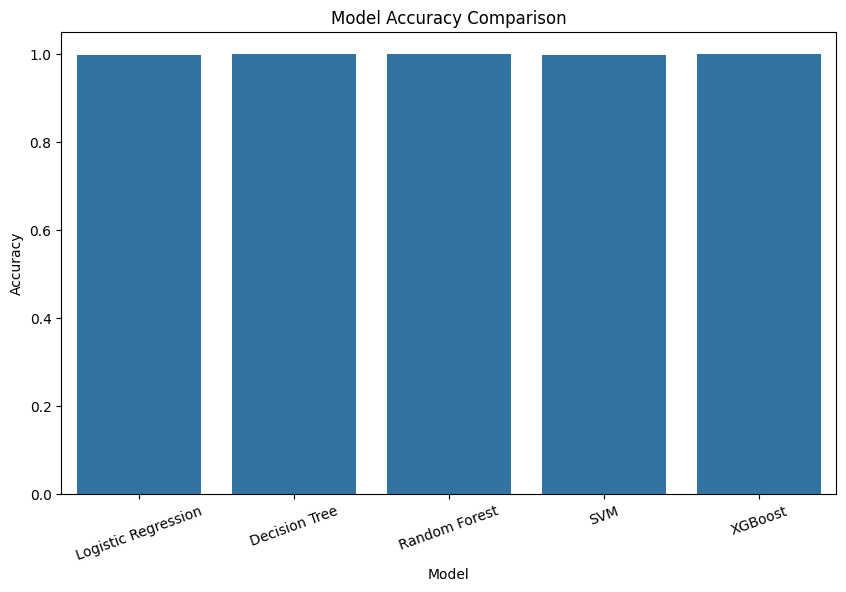

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)

plt.show()

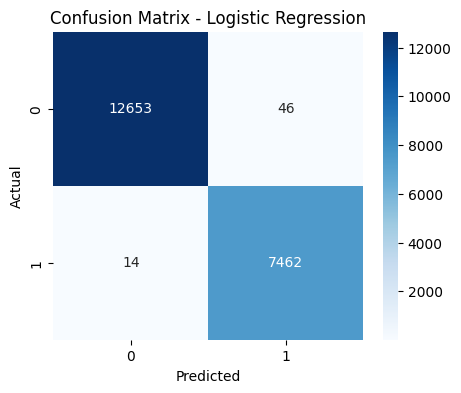

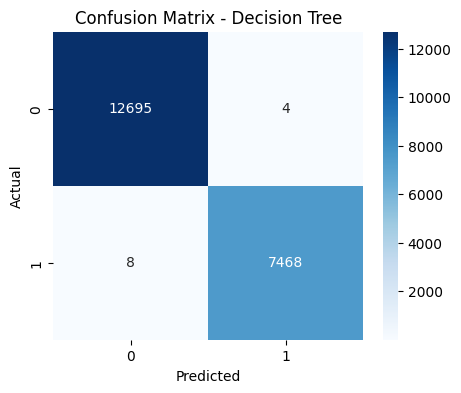

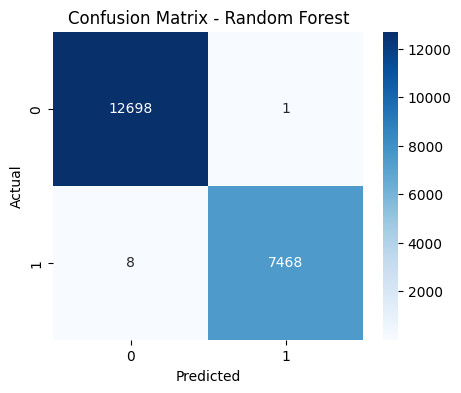

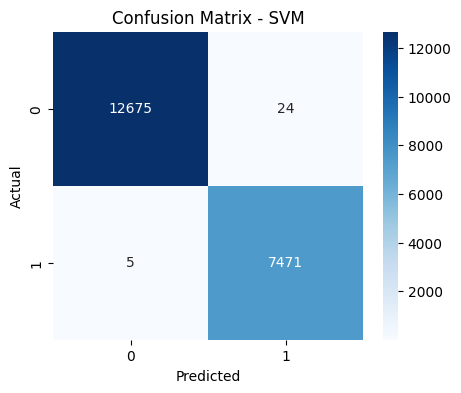

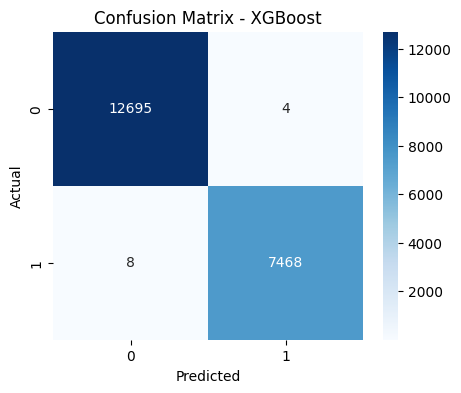

In [41]:
for name, model in models.items():


    y_pred = model.predict(X_test_numeric)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [43]:
for name, model in models.items():


    y_pred = model.predict(X_test_numeric)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred
        )
    )


Logistic Regression
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     12699
         1.0       0.99      1.00      1.00      7476

    accuracy                           1.00     20175
   macro avg       1.00      1.00      1.00     20175
weighted avg       1.00      1.00      1.00     20175


Decision Tree
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     12699
         1.0       1.00      1.00      1.00      7476

    accuracy                           1.00     20175
   macro avg       1.00      1.00      1.00     20175
weighted avg       1.00      1.00      1.00     20175


Random Forest
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     12699
         1.0       1.00      1.00      1.00      7476

    accuracy                           1.00     20175
   macro avg       1.00      1.00      1.00     20175
weighted avg       1.00

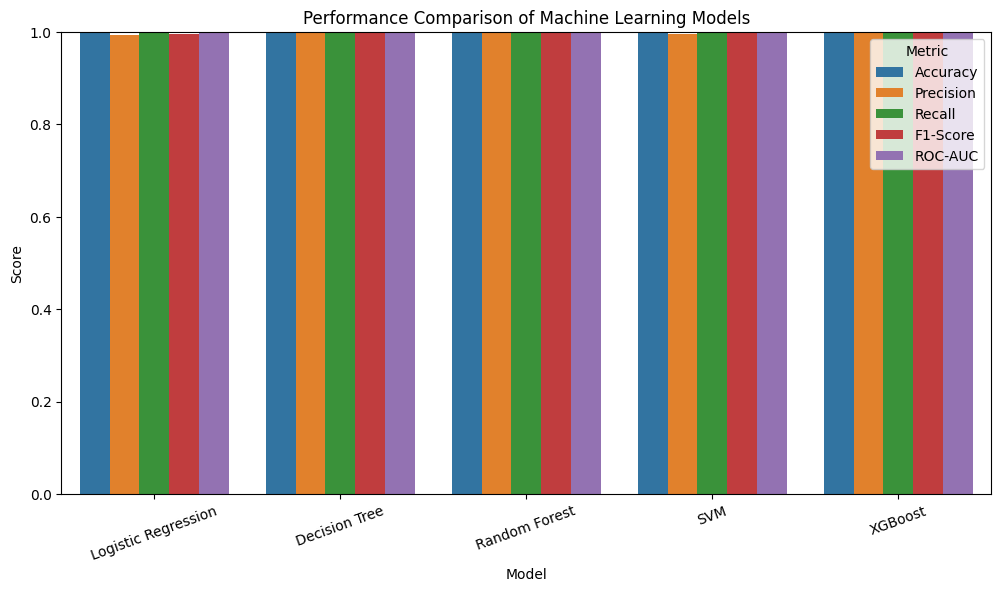

In [44]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.show()

In [45]:
results_sorted = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

print(results_sorted)

                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
2        Random Forest  0.999554   0.999866  0.998930  0.999398  0.999997
4              XGBoost  0.999405   0.999465  0.998930  0.999197  0.999997
1        Decision Tree  0.999405   0.999465  0.998930  0.999197  0.999307
3                  SVM  0.998563   0.996798  0.999331  0.998063  0.999952
0  Logistic Regression  0.997026   0.993873  0.998127  0.995996  0.999895


In [46]:
best_model_name = results_sorted.iloc[0]["Model"]

print("Best Model:", best_model_name)

Best Model: Random Forest


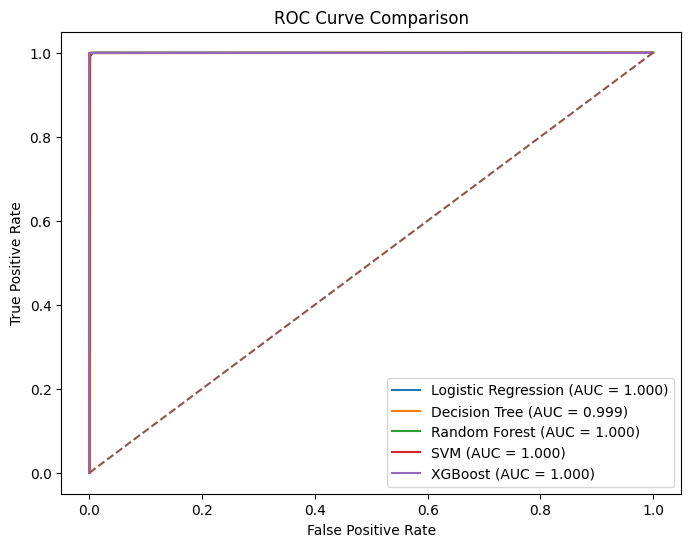

In [48]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, model in models.items():


    y_prob = model.predict_proba(X_test_numeric)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

In [49]:
best_model = models[best_model_name]

print("Selected model:", best_model_name)

Selected model: Random Forest


In [50]:
import joblib

joblib.dump(
    best_model,
    "phishguard_model.pkl"
)

['phishguard_model.pkl']

In [51]:
feature_columns = X.columns.tolist()

print("Features used by the model:")
for i, feature in enumerate(feature_columns, 1):
    print(i, feature)

Features used by the model:
1 URL
2 url_length
3 has_ip_address
4 dot_count
5 https_flag
6 url_entropy
7 token_count
8 subdomain_count
9 query_param_count
10 tld_length
11 path_length
12 has_hyphen_in_domain
13 number_of_digits
14 tld_popularity
15 suspicious_file_extension
16 domain_name_length
17 percentage_numeric_chars


In [52]:
print(X.dtypes)

URL                           object
url_length                     int64
has_ip_address                 int64
dot_count                      int64
https_flag                     int64
url_entropy                  float64
token_count                    int64
subdomain_count                int64
query_param_count              int64
tld_length                     int64
path_length                    int64
has_hyphen_in_domain           int64
number_of_digits               int64
tld_popularity                 int64
suspicious_file_extension      int64
domain_name_length             int64
percentage_numeric_chars     float64
dtype: object


In [53]:

X = df.drop(["ClassLabel", "URL"], axis=1)
y = df["ClassLabel"]

print("Features used by the model:")
for i, feature in enumerate(X.columns, start=1):
    print(i, feature)

print("\nTotal features:", X.shape[1])

Features used by the model:
1 url_length
2 has_ip_address
3 dot_count
4 https_flag
5 url_entropy
6 token_count
7 subdomain_count
8 query_param_count
9 tld_length
10 path_length
11 has_hyphen_in_domain
12 number_of_digits
13 tld_popularity
14 suspicious_file_extension
15 domain_name_length
16 percentage_numeric_chars

Total features: 16


In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [55]:
results = []

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    print("Accuracy:", accuracy)

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(6))

Training: Logistic Regression
Accuracy: 0.9970260223048327
Training: Decision Tree
Accuracy: 0.9994052044609666
Training: Random Forest
Accuracy: 0.9995539033457249
Training: SVM
Accuracy: 0.9985625774473358
Training: XGBoost
Accuracy: 0.9994052044609666

Model Comparison:
                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0  Logistic Regression  0.997026   0.993873  0.998127  0.995996  0.999895
1        Decision Tree  0.999405   0.999465  0.998930  0.999197  0.999307
2        Random Forest  0.999554   0.999866  0.998930  0.999398  0.999997
3                  SVM  0.998563   0.996798  0.999331  0.998063  0.999952
4              XGBoost  0.999405   0.999465  0.998930  0.999197  0.999997


In [56]:
best_model_name = "Random Forest"
best_model = models[best_model_name]

print("Selected Best Model:", best_model_name)

Selected Best Model: Random Forest


In [57]:
import joblib

joblib.dump(best_model, "phishguard_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [58]:
import re
import math
from urllib.parse import urlparse

def extract_features(url):

    # Add scheme if the user doesn't enter one
    if not url.startswith(("http://", "https://")):
        url = "http://" + url

    parsed = urlparse(url)

    domain = parsed.netloc
    path = parsed.path
    query = parsed.query

    # Remove port number from domain
    domain_without_port = domain.split(":")[0]

    # 1. URL length
    url_length = len(url)

    # 2. Check whether URL contains an IP address
    has_ip_address = 1 if re.match(
        r"^(?:\d{1,3}\.){3}\d{1,3}$",
        domain_without_port
    ) else 0

    # 3. Number of dots
    dot_count = url.count(".")

    # 4. HTTPS flag
    https_flag = 1 if parsed.scheme == "https" else 0

    # 5. URL entropy
    if len(url) > 0:
        frequency = {}
        for char in url:
            frequency[char] = frequency.get(char, 0) + 1

        url_entropy = 0
        for count in frequency.values():
            probability = count / len(url)
            url_entropy -= probability * math.log2(probability)
    else:
        url_entropy = 0

    # 6. Token count
    tokens = re.split(r"[/\-_.?=&:]+", url)
    tokens = [token for token in tokens if token]
    token_count = len(tokens)

    # 7. Subdomain count
    domain_parts = domain_without_port.split(".")
    subdomain_count = max(len(domain_parts) - 2, 0)

    # 8. Query parameter count
    query_param_count = 0 if not query else len(query.split("&"))

    # 9. TLD length
    tld = domain_parts[-1] if len(domain_parts) > 1 else ""
    tld_length = len(tld)

    # 10. Path length
    path_length = len(path)

    # 11. Hyphen in domain
    has_hyphen_in_domain = 1 if "-" in domain_without_port else 0

    # 12. Number of digits
    number_of_digits = sum(char.isdigit() for char in url)

    # 13. TLD popularity
    common_tlds = {
        "com", "org", "net", "edu", "gov",
        "in", "co", "uk", "de", "io"
    }

    tld_popularity = 1 if tld.lower() in common_tlds else 0

    # 14. Suspicious file extension
    suspicious_extensions = (
        ".exe", ".scr", ".zip", ".rar",
        ".bat", ".cmd", ".msi", ".apk"
    )

    suspicious_file_extension = 1 if any(
        path.lower().endswith(ext)
        for ext in suspicious_extensions
    ) else 0

    # 15. Domain name length
    domain_name_length = len(domain_without_port)

    # 16. Percentage of numeric characters
    percentage_numeric_chars = (
        number_of_digits / len(url) * 100
        if len(url) > 0 else 0
    )

    return [
        url_length,
        has_ip_address,
        dot_count,
        https_flag,
        url_entropy,
        token_count,
        subdomain_count,
        query_param_count,
        tld_length,
        path_length,
        has_hyphen_in_domain,
        number_of_digits,
        tld_popularity,
        suspicious_file_extension,
        domain_name_length,
        percentage_numeric_chars
    ]

In [59]:
test_url = "https://www.google.com"

features = extract_features(test_url)

print("Extracted features:")
print(features)

print("Number of features:", len(features))

Extracted features:
[22, 0, 2, 1, 3.663532754804254, 4, 1, 0, 3, 0, 0, 0, 1, 0, 14, 0.0]
Number of features: 16


In [60]:
import numpy as np

test_features = np.array(features).reshape(1, -1)

prediction = best_model.predict(test_features)[0]

print("Prediction:", prediction)

Prediction: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [61]:
prediction_probability = best_model.predict_proba(test_features)[0]

print("Prediction probabilities:", prediction_probability)

Prediction probabilities: [0. 1.]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [62]:
feature_columns = [
    "url_length",
    "has_ip_address",
    "dot_count",
    "https_flag",
    "url_entropy",
    "token_count",
    "subdomain_count",
    "query_param_count",
    "tld_length",
    "path_length",
    "has_hyphen_in_domain",
    "number_of_digits",
    "tld_popularity",
    "suspicious_file_extension",
    "domain_name_length",
    "percentage_numeric_chars"
]

test_features_df = pd.DataFrame(
    [features],
    columns=feature_columns
)

prediction = best_model.predict(test_features_df)[0]
probability = best_model.predict_proba(test_features_df)[0]

print("Prediction:", prediction)
print("Probabilities:", probability)

Prediction: 1.0
Probabilities: [0. 1.]


In [63]:
print(df.groupby("ClassLabel")["URL"].apply(list).head())

ClassLabel
0.0    [https://keraekken-loagginnusa.godaddysites.co...
1.0    [https://stackoverflow.com/questions/tagged/ph...
Name: URL, dtype: object


In [64]:
if prediction == 0:
    result = "Phishing"
else:
    result = "Legitimate"

print("URL:", test_url)
print("Prediction:", result)

URL: https://www.google.com
Prediction: Legitimate


In [65]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import re
import math
from urllib.parse import urlparse


# Load trained model
model = joblib.load("phishguard_model.pkl")


# Feature extraction function
def extract_features(url):

    if not url.startswith(("http://", "https://")):
        url = "http://" + url

    parsed = urlparse(url)

    domain = parsed.netloc
    path = parsed.path
    query = parsed.query

    domain_without_port = domain.split(":")[0]

    # URL length
    url_length = len(url)

    # IP address
    has_ip_address = 1 if re.match(
        r"^(?:\d{1,3}\.){3}\d{1,3}$",
        domain_without_port
    ) else 0

    # Dot count
    dot_count = url.count(".")

    # HTTPS
    https_flag = 1 if parsed.scheme == "https" else 0

    # URL entropy
    if len(url) > 0:
        frequency = {}

        for char in url:
            frequency[char] = frequency.get(char, 0) + 1

        url_entropy = 0

        for count in frequency.values():
            probability = count / len(url)
            url_entropy -= probability * math.log2(probability)
    else:
        url_entropy = 0

    # Token count
    tokens = re.split(r"[/\-_.?=&:]+", url)
    tokens = [token for token in tokens if token]
    token_count = len(tokens)

    # Subdomain count
    domain_parts = domain_without_port.split(".")
    subdomain_count = max(len(domain_parts) - 2, 0)

    # Query parameters
    query_param_count = 0 if not query else len(query.split("&"))

    # TLD length
    tld = domain_parts[-1] if len(domain_parts) > 1 else ""
    tld_length = len(tld)

    # Path length
    path_length = len(path)

    # Hyphen in domain
    has_hyphen_in_domain = 1 if "-" in domain_without_port else 0

    # Number of digits
    number_of_digits = sum(char.isdigit() for char in url)

    # TLD popularity
    common_tlds = {
        "com", "org", "net", "edu", "gov",
        "in", "co", "uk", "de", "io"
    }

    tld_popularity = 1 if tld.lower() in common_tlds else 0

    # Suspicious file extension
    suspicious_extensions = (
        ".exe", ".scr", ".zip", ".rar",
        ".bat", ".cmd", ".msi", ".apk"
    )

    suspicious_file_extension = 1 if any(
        path.lower().endswith(ext)
        for ext in suspicious_extensions
    ) else 0

    # Domain name length
    domain_name_length = len(domain_without_port)

    # Percentage numeric characters
    percentage_numeric_chars = (
        number_of_digits / len(url) * 100
        if len(url) > 0 else 0
    )

    return [
        url_length,
        has_ip_address,
        dot_count,
        https_flag,
        url_entropy,
        token_count,
        subdomain_count,
        query_param_count,
        tld_length,
        path_length,
        has_hyphen_in_domain,
        number_of_digits,
        tld_popularity,
        suspicious_file_extension,
        domain_name_length,
        percentage_numeric_chars
    ]


# Page title
st.title("🛡️ PhishGuard")
st.write("Machine Learning Based Phishing URL Detection")

st.divider()

# URL input
url = st.text_input(
    "Enter a URL to check:",
    placeholder="https://example.com"
)


# Prediction button
if st.button("Check URL"):

    if url.strip() == "":
        st.warning("Please enter a URL.")

    else:

        features = extract_features(url)

        feature_columns = [
            "url_length",
            "has_ip_address",
            "dot_count",
            "https_flag",
            "url_entropy",
            "token_count",
            "subdomain_count",
            "query_param_count",
            "tld_length",
            "path_length",
            "has_hyphen_in_domain",
            "number_of_digits",
            "tld_popularity",
            "suspicious_file_extension",
            "domain_name_length",
            "percentage_numeric_chars"
        ]

        features_df = pd.DataFrame(
            [features],
            columns=feature_columns
        )

        prediction = model.predict(features_df)[0]

        probability = model.predict_proba(features_df)[0]

        if prediction == 0:

            st.error("⚠️ Phishing URL")

            st.write(
                f"Phishing probability: {probability[0] * 100:.2f}%"
            )

        else:

            st.success("✅ Legitimate URL")

            st.write(
                f"Legitimate probability: {probability[1] * 100:.2f}%"
            )

Writing app.py


In [66]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 44.2 MB/s eta 0:00:00


In [67]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.9.3) ...
Setting up cloudflared (2026.9.3) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [68]:
!streamlit run app.py --server.port 8501 &>/content/logs.txt &

In [70]:
!cat /content/logs.txt



2026-10-04 12:16:58.920 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.190.163.137:8501

  Stopping...


In [71]:
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [72]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Sun, 04 Oct 2026 12:30:42 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6463
last-modified: Sun, 04 Oct 2026 12:15:40 GMT
etag: "0e0f2bbd9b7d7d9bed274eb711dd6945"
cache-control: no-cache



In [73]:
!cloudflared tunnel --url http://localhost:8501

2026-10-04T12:31:03Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-04T12:31:03Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-04T12:31:07Z INF +--------------------------------------------------------------------------------------------+
2026-10-04T12:31:07Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-04T12:31:07Z INF |  https://statements-refresh-percentage-anime.trycloudf

In [75]:
import os

print(os.path.exists("app.py"))
print(os.path.exists("phishguard_model.pkl"))

True
True


In [76]:
!cloudflared tunnel --url http://localhost:8501 > /content/cloudflared.log 2>&1 &

In [77]:
!grep -o "https://[-a-zA-Z0-9]*\.trycloudflare\.com" /content/cloudflared.log

https://analytical-strand-sampling-marriage.trycloudflare.com


In [78]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [79]:
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [80]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Sun, 04 Oct 2026 12:48:26 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6463
last-modified: Sun, 04 Oct 2026 12:15:40 GMT
etag: "0e0f2bbd9b7d7d9bed274eb711dd6945"
cache-control: no-cache



In [81]:
!pip freeze | grep -E "streamlit|pandas|numpy|scikit-learn|xgboost|joblib" > requirements.txt

In [82]:
!cat requirements.txt

geopandas==1.1.4
joblib==1.6.0
numpy==2.1.3
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
scikit-learn==1.6.1
sklearn-pandas==2.2.0
streamlit==1.65.0
xgboost==3.4.1


In [83]:
!ls -lh app.py phishguard_model.pkl requirements.txt

-rw-r--r-- 1 root root 4.3K Oct  4 12:15 app.py
-rw-r--r-- 1 root root 2.1M Oct  4 12:11 phishguard_model.pkl
-rw-r--r-- 1 root root  205 Oct  4 12:51 requirements.txt


In [84]:
%%writefile requirements.txt
joblib==1.6.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
streamlit==1.65.0
xgboost==3.4.1

Overwriting requirements.txt


In [85]:
!cat requirements.txt

joblib==1.6.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
streamlit==1.65.0
xgboost==3.4.1


In [87]:
!ls -lh app.py phishguard_model.pkl requirements.txt

-rw-r--r-- 1 root root 4.3K Oct  4 12:15 app.py
-rw-r--r-- 1 root root 2.1M Oct  4 12:11 phishguard_model.pkl
-rw-r--r-- 1 root root   94 Oct  4 12:52 requirements.txt


In [88]:
%%writefile README.md

# 🛡️ PhishGuard

## Machine Learning Based Phishing URL Detection

PhishGuard is a machine learning-based web application that detects whether a given URL is **Phishing** or **Legitimate**.

The system extracts lexical and structural features from the URL and uses a trained machine learning model to make the prediction.

## Features

- URL-based phishing detection
- 16 lexical and structural URL features
- Multiple machine learning models compared
- Random Forest selected as the best-performing model
- Streamlit-based user interface
- Probability-based prediction
- Online deployment using Streamlit and Cloudflare Tunnel

## Machine Learning Models

The following models were compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)
5. XGBoost

### Best Model

Random Forest achieved the best overall performance on the test dataset.

| Metric | Score |
|---|---:|
| Accuracy | 99.9554% |
| Precision | 99.9866% |
| Recall | 99.8930% |
| F1-Score | 99.9398% |
| ROC-AUC | 0.999997 |

## URL Features

The model uses the following features:

- URL length
- IP address presence
- Dot count
- HTTPS flag
- URL entropy
- Token count
- Subdomain count
- Query parameter count
- TLD length
- Path length
- Hyphen in domain
- Number of digits
- TLD popularity
- Suspicious file extension
- Domain name length
- Percentage of numeric characters

## Project Structure

```text
PhishGuard/
│
├── app.py
├── phishguard_model.pkl
├── requirements.txt
└── README.md

Writing README.md


In [89]:
pip install -r requirements.txt

In [90]:
!ls -lh README.md

-rw-r--r-- 1 root root 1.5K Oct  4 12:54 README.md


In [91]:
from google.colab import files

files.download("app.py")
files.download("phishguard_model.pkl")
files.download("requirements.txt")
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>